In [9]:
import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt
from tqdm import trange

In [10]:
# from dualwcfm.trainers.dual_trainer import DualTrainer, DualTrainerConfig
# from dualwcfm.visualization import plot_2d_flow_trajectories
# from dualwcfm.models.cfm import ConditionalFlowMatching
# from dualwcfm.trainers.dynamic_trainer import DynamicTrainer
# from dualwcfm.models.cfm import torch_wrapper
# from dualwcfm.trainers.wcfm import CFMTrainerConfig
from torchcfm.models.models import MLP

In [11]:
# ! pip install torchcfm

In [12]:
from dualwcfm.distributions.distribution import Distribution
from dualwcfm.distributions.coupling import FixedSizeCouplingDistribution, FunctionalCouplingDistribution
from dualwcfm.distributions import CouplingDistribution, RotatedShapeCoupling, Simple2DGaussianDistribution, RotatedDistribution, MoonDistribution

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [14]:
import torch
import torch.nn as nn
from torchdyn.core import NeuralODE

class LagrangianFlowField(nn.Module):
    """
    Wraps a velocity network to handle 'Source Conditioning'.
    State z = [x_t, x_0] (Dimension 2*D)
    Dynamics: dx/dt = net(x_t, x_0, t), dx_0/dt = 0
    """
    def __init__(self, net, dim):
        super().__init__()
        self.net = net
        self.dim = dim

    def forward(self, x):
        x_t = x[:, :self.dim]      # Current Position (Evolving)
        x_0 = x[:, self.dim:2*self.dim]      # Initial Position (Constant Context)

        # if isinstance(t, torch.Tensor) and t.dim() == 0:
        #      t = t.repeat(z.shape[0], 1)
        # elif isinstance(t, float):
        #      t = torch.full((z.shape[0], 1), t).to(z.device)

        # net_input = torch.cat([x_t, x_0, t], dim=1)

        v_x = self.net(x)
        v_c = torch.zeros_like(x_0)
        return torch.cat([v_x, v_c], dim=1)

#### 定义“原始耦合”的采样器

A_coup=
 tensor([[-1.0000, -0.4330],
        [ 1.7321, -0.2500]])
b_shift= tensor([-4.,  0.])
Theoretical nu' mean = tensor([-13.1651,   8.4103])
Theoretical nu' cov =
 tensor([[ 0.0742, -0.1015],
        [-0.1015,  0.1914]])


<Figure size 800x800 with 0 Axes>

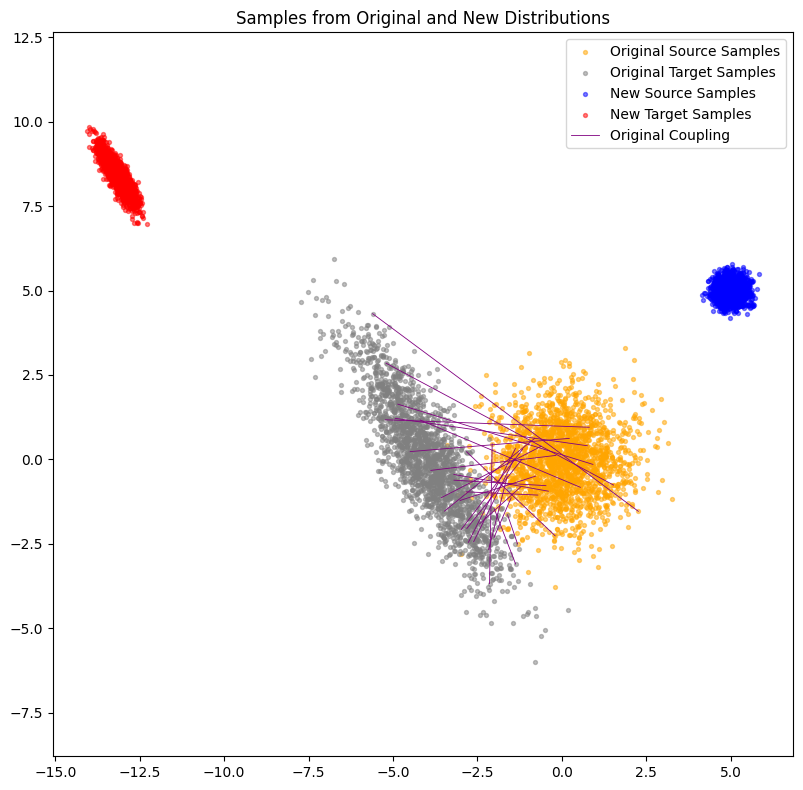

In [15]:
import math
import torch

class FunctionalDistribution:
    def __init__(self, sampler_fn):
        self.sampler_fn = sampler_fn
    def sample(self, n):
        return self.sampler_fn(n)

# --------- Coupling: y = A x + b_shift ----------
theta = math.pi*2 / 3  # 60 degrees
R = torch.tensor([[math.cos(theta), -math.sin(theta)],
                  [math.sin(theta),  math.cos(theta)]], dtype=torch.float32)

s1, s2 = 2.0, 0.5
D = torch.diag(torch.tensor([s1, s2], dtype=torch.float32))

A_coup = R @ D  # (2,2)
b_shift = torch.tensor([-4.0, 0.0], dtype=torch.float32)  # (2,)
b_shift_new = torch.tensor([-6.0, 1.0], dtype=torch.float32)

def linear_coupling(n: int):
    x = torch.randn(n, 2)
    y = x @ A_coup.T + b_shift
    return x, y



coupling_dist = FunctionalCouplingDistribution(linear_coupling)
source_dist, target_dist = coupling_dist.get_marginals()

print("A_coup=\n", A_coup)
print("b_shift=", b_shift)



new_source_dist = Simple2DGaussianDistribution(mean=torch.tensor([5.0, 5.0]), std=torch.tensor([0.25, 0.25]))

# --- Theoretical nu' from pushforward: Y' = A X' + b, X'~N(m', 0.25^2 I) ---
m_prime = torch.tensor([5.0, 5.0], dtype=torch.float32)
Sigma_mu_prime = (0.25 ** 2) * torch.eye(2, dtype=torch.float32)  # 0.0625 I

mean_nu_prime = A_coup @ m_prime + b_shift_new
cov_nu_prime  = A_coup @ Sigma_mu_prime @ A_coup.T
mean_nu_prime = mean_nu_prime.detach()
cov_nu_prime  = cov_nu_prime.detach()

A_const = A_coup.clone().detach()
b_const = b_shift.clone().detach()

print("Theoretical nu' mean =", mean_nu_prime)
print("Theoretical nu' cov =\n", cov_nu_prime)

# --- Build a distribution object for nu' via functional sampling (supports full covariance) ---
def sample_gaussian_with_cov(n: int, mean: torch.Tensor, cov: torch.Tensor):
    mean = mean.cpu()
    cov  = cov.cpu()
    L = torch.linalg.cholesky(cov)
    z = torch.randn(n, 2)          # CPU
    return mean + z @ L.T          # CPU


def nu_prime_sampler(n: int):
    mean = mean_nu_prime
    cov  = cov_nu_prime
    return sample_gaussian_with_cov(n, mean, cov)

new_target_dist = FunctionalDistribution(nu_prime_sampler)  # ✅ 用函数分布表示 nu'


# coupling_dist = RotatedShapeCoupling(
#     centers=[[0,0], [1.5,0], [-1.5,0], [0,1.5], [0,-1.5]],
#     source_scale=0.2,
#     target_scale=0.2,
#     rotation_degrees=90.0,
#     source_shift=(0.0, 0.0),
#     target_shift=(0.0, 0.0),
#     device=device
# )
# new_coupling_dist = RotatedShapeCoupling(
#     centers=[[0,0], [1.5,0], [-1.5,0], [0,1.5], [0,-1.5]],
#     source_scale=0.2,
#     target_scale=0.2,
#     rotation_degrees=90.0,
#     source_shift=(2.5, 2.5),
#     target_shift=(2.5, -2.5),
# )
# source_dist, target_dist = coupling_dist.get_marginals()
# new_source_dist, new_target_dist = new_coupling_dist.get_marginals()

plt.figure(figsize=(8, 8))
n_samples = 2000
coupling_samples = coupling_dist.coupling_sample(n_samples)
source_samples = coupling_samples[0].cpu().numpy()
target_samples = coupling_samples[1].cpu().numpy()
new_source_samples = new_source_dist.sample(n_samples).cpu().numpy()
new_target_samples = new_target_dist.sample(n_samples).cpu().numpy()

fig = plt.figure(figsize=(8, 8))
plt.scatter(source_samples[:, 0], source_samples[:, 1], c='orange', s=8, alpha=0.5, label='Original Source Samples')
plt.scatter(target_samples[:, 0], target_samples[:, 1], c='grey', s=8, alpha=0.5, label='Original Target Samples')
plt.scatter(new_source_samples[:, 0], new_source_samples[:, 1], c='blue', s=8, alpha=0.5, label='New Source Samples')
plt.scatter(new_target_samples[:, 0], new_target_samples[:, 1], c='red', s=8, alpha=0.5, label='New Target Samples')
plt.plot([source_samples[:25, 0], target_samples[:25, 0]], [source_samples[:25, 1], target_samples[:25, 1]], c='purple', alpha=1.0, lw=0.6, label='Original Coupling')
plt.title('Samples from Original and New Distributions')
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())
plt.tight_layout()
plt.axis("equal")
plt.show()

## Learn marginal Conditional Flow Matching

In [16]:
from dualwcfm.visualization import plot_2d_flow_trajectories
from dualwcfm.cfm import ConditionalFlowMatching

Training Marginal Bridges: 100%|██████████| 2500/2500 [00:22<00:00, 109.43it/s, Loss mu=0.42, Loss nu=0.92]  


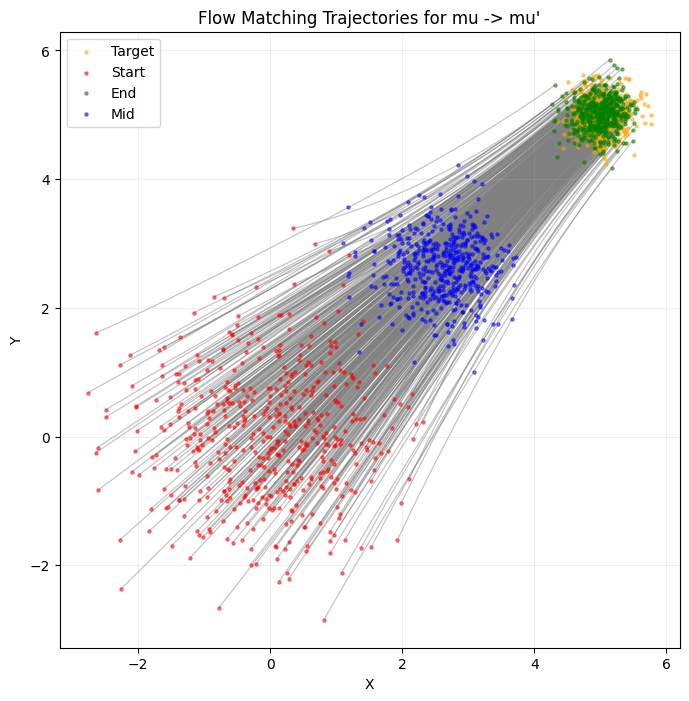

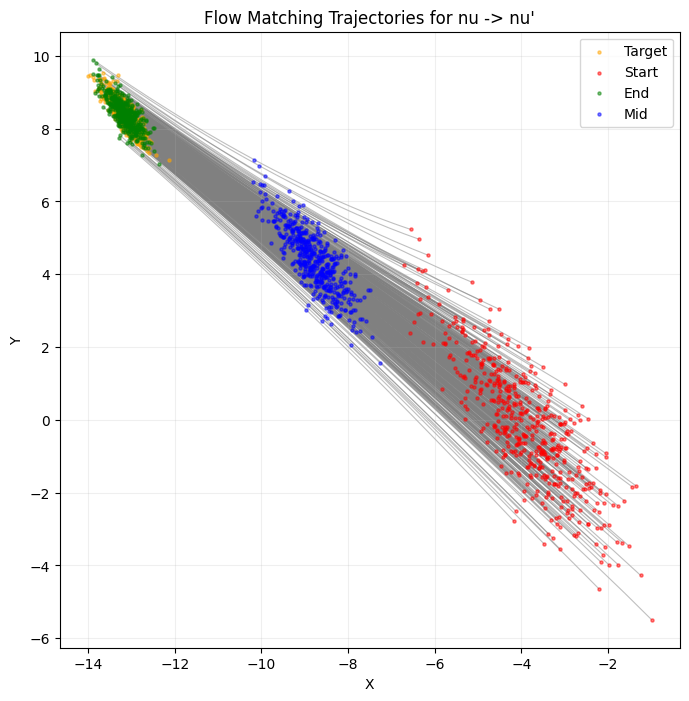

In [17]:
flow_mu = MLP(dim=2, out_dim=2, w=64, time_varying=True).to(device)
flow_nu = MLP(dim=2, out_dim=2, w=64, time_varying=True).to(device)

optimizer_mu = optim.Adam(flow_mu.parameters(), lr=1e-3)
optimizer_nu = optim.Adam(flow_nu.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

batch_size = 2048
epochs_marginal = 2500
sigma = 0.1

def interpolate(x0, x1, t, sigma):
    return (1 - t) * x0 + t * x1 + sigma * torch.randn_like(x0) * torch.sqrt(t * (1 - t))

pbar = trange(epochs_marginal, desc="Training Marginal Bridges")
for epoch in pbar:
    x0, y0 = coupling_dist.coupling_sample(batch_size)
    x1, y1 = new_source_dist.sample(batch_size), new_target_dist.sample(batch_size)
    x0, x1, y0, y1 = x0.to(device), x1.to(device), y0.to(device), y1.to(device)

    t = torch.rand(batch_size, 1).to(device)
    xt, yt = interpolate(x0, x1, t, sigma), interpolate(y0, y1, t, sigma)

    u_t, v_t = flow_mu(torch.cat([xt, t], dim=1)), flow_nu(torch.cat([yt, t], dim=1))
    target_u_t, target_v_t = x1 - x0, y1 - y0

    optimizer_mu.zero_grad()
    optimizer_nu.zero_grad()

    loss_mu = loss_fn(u_t, target_u_t)
    loss_mu.backward()
    optimizer_mu.step()

    loss_nu = loss_fn(v_t, target_v_t)
    loss_nu.backward()
    optimizer_nu.step()

    pbar.set_postfix({"Loss mu": loss_mu.item(), "Loss nu": loss_nu.item()})


cfm_mu = ConditionalFlowMatching(source_dist, new_source_dist, flow_mu, sigma=sigma)
cfm_nu = ConditionalFlowMatching(target_dist, new_target_dist, flow_nu, sigma=sigma)

n_samples = 500
n_timesteps = 20

time = torch.linspace(0, 1, n_timesteps)
traj_mu = cfm_mu.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
traj_nu = cfm_nu.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
target_mu_samples = new_source_dist.sample(n_samples).cpu().numpy()
target_nu_samples = new_target_dist.sample(n_samples).cpu().numpy()

plot_2d_flow_trajectories(trajectories=traj_mu, t=time, n_trajectories=n_samples, target_points=target_mu_samples, title=f"Flow Matching Trajectories for mu -> mu'")
plot_2d_flow_trajectories(trajectories=traj_nu, t=time, n_trajectories=n_samples, target_points=target_nu_samples, title=f"Flow Matching Trajectories for nu -> nu'")

## Testing coupling evolution

In [18]:
dataset_size = 10
current_coupling_dist = FixedSizeCouplingDistribution(coupling_dist, size=dataset_size)
current_coupling_dist.dataset = current_coupling_dist.dataset.clone().cpu() # (2, dataset_size, dim)

n_iterations = 10
delta = 1.0 / n_iterations

trajectories = [current_coupling_dist.dataset.clone().cpu().numpy()]

for iteration in range(n_iterations):
    t_current = iteration / n_iterations
    x, y = current_coupling_dist.dataset[0].to(device), current_coupling_dist.dataset[1].to(device)

    t_tensor = torch.full((x.shape[0], 1), t_current).to(device)

    u_t = flow_mu(torch.cat([x, t_tensor], dim=1))
    v_t = flow_nu(torch.cat([y, t_tensor], dim=1))

    x_next = x.detach() + delta * u_t
    y_next = y.detach() + delta * v_t

    x_next = x_next.detach().cpu()
    y_next = y_next.detach().cpu()

    current_coupling_dist.dataset = torch.stack([x_next, y_next], dim=0)

    trajectories.append(current_coupling_dist.dataset.clone().cpu().numpy())

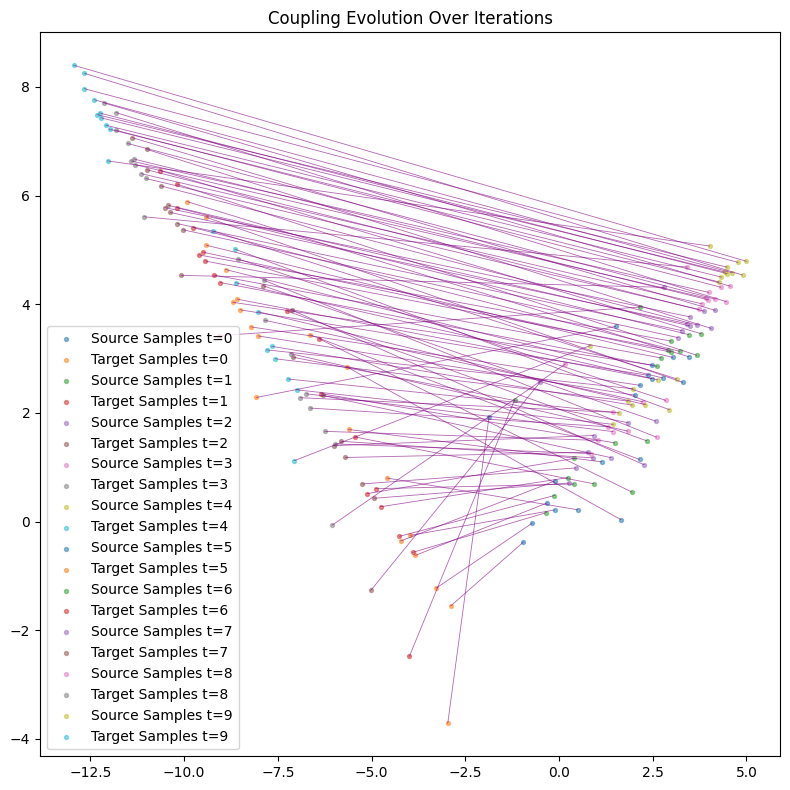

In [19]:
fig = plt.figure(figsize=(8, 8))
for i in range(len(trajectories)-1):
    source_samples = trajectories[i][0]
    target_samples = trajectories[i][1]
    plt.scatter(source_samples[:, 0], source_samples[:, 1], s=8, alpha=0.5, label=f'Source Samples t={i}')
    plt.scatter(target_samples[:, 0], target_samples[:, 1], s=8, alpha=0.5, label=f'Target Samples t={i}')
    plt.plot([source_samples[:25, 0], target_samples[:25, 0]], [source_samples[:25, 1], target_samples[:25, 1]], c='purple', alpha=0.6, lw=0.6)
plt.title('Coupling Evolution Over Iterations')
plt.tight_layout()
plt.legend()
plt.show()

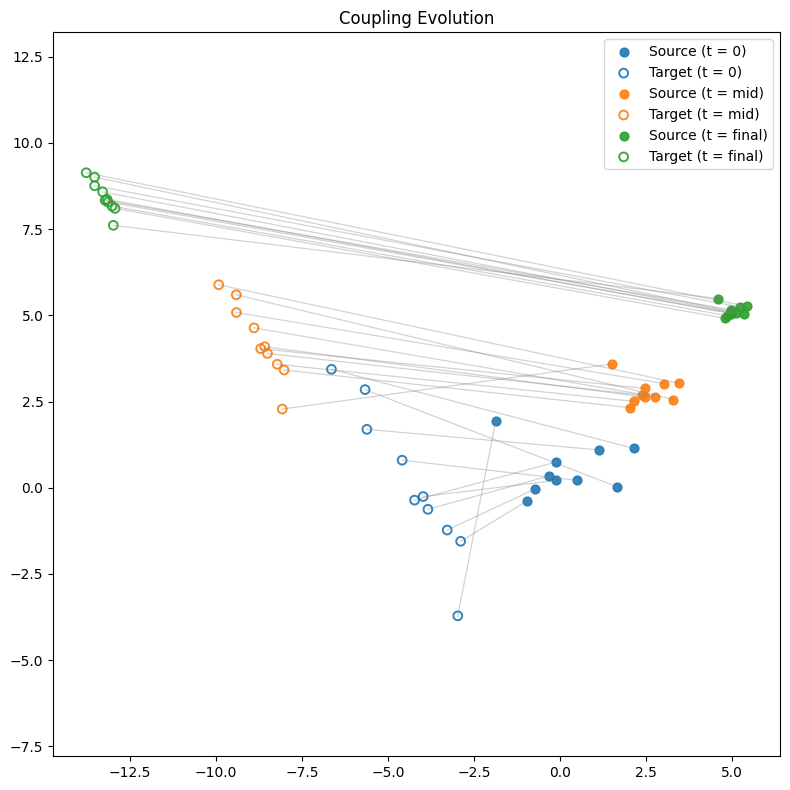

In [20]:
fig = plt.figure(figsize=(8, 8))

# 只选 3 个时间点：初始 / 中间 / 最终
idxs = [
    0,
    (len(trajectories) - 1) // 2,
    len(trajectories) - 1,
]

colors = ["tab:blue", "tab:orange", "tab:green"]
labels = ["t = 0", "t = mid", "t = final"]

for i, c, lab in zip(idxs, colors, labels):
    source_samples = trajectories[i][0]
    target_samples = trajectories[i][1]

    # source：实心点
    plt.scatter(
        source_samples[:, 0],
        source_samples[:, 1],
        s=40,
        alpha=0.9,
        color=c,
        label=f"Source ({lab})",
    )

    # target：空心点
    plt.scatter(
        target_samples[:, 0],
        target_samples[:, 1],
        s=40,
        alpha=0.9,
        facecolors="none",
        edgecolors=c,
        linewidths=1.4,
        label=f"Target ({lab})",
    )

    # coupling 连线（淡灰）
    plt.plot(
        [source_samples[:, 0], target_samples[:, 0]],
        [source_samples[:, 1], target_samples[:, 1]],
        c="grey",
        alpha=0.35,
        lw=0.9,
    )

plt.title("Coupling Evolution")
plt.axis("equal")
plt.legend()
plt.tight_layout()
plt.show()


In [21]:
import numpy as np

def plot_iteration_diagnostics(step, x_ref, y_ref, f_net, g_net, flow_model, device):
    """Visualizes the coupling, the learned weights, and the vector field."""
    x_ref_np = x_ref.detach().cpu().numpy()
    y_ref_np = y_ref.detach().cpu().numpy()
    with torch.no_grad():
        a = f_net(x_ref).view(-1)
        b = g_net(y_ref).view(-1)

        log_weights = a + b

    # Grid for vector field
    grid_n = 20
    x = np.linspace(-10, 10, grid_n)
    y = np.linspace(-10, 10, grid_n)
    X, Y = np.meshgrid(x, y)
    grid = torch.tensor(np.stack([X.flatten(), Y.flatten()], axis=1), dtype=torch.float32).to(device)

    # Flow Vector Field (at t=0 for this step)
    t_zeros = torch.zeros(grid.shape[0], 1).to(device)
    with torch.no_grad():
        vectors = flow_model(torch.cat([grid, grid, t_zeros], dim=1)).cpu().numpy()
        # vectors = flow_model(torch.cat([grid, torch.randn_like(grid), t_zeros], dim=1)).cpu().numpy()
    U = vectors[:, 0].reshape(grid_n, grid_n)
    V = vectors[:, 1].reshape(grid_n, grid_n)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sc = axes[0].scatter(x_ref_np[:, 0], x_ref_np[:, 1], c=log_weights.cpu().numpy(), cmap='viridis', s=5, alpha=0.6)
    axes[0].set_title(f"Step {step}: Source Samples\n(Color = Log Learned Weight)")
    plt.colorbar(sc, ax=axes[0])
    axes[0].set_xlim(-10, 10); axes[0].set_ylim(-10, 10)

    axes[1].scatter(y_ref_np[:, 0], y_ref_np[:, 1], c=log_weights.cpu().numpy(), s=5, alpha=0.3, label='Target Coupling Y')
    axes[1].set_title(f"Step {step}: Target Samples")
    axes[1].set_xlim(-10, 10); axes[1].set_ylim(-10, 10)

    axes[2].quiver(X, Y, U, V, color='blue', alpha=0.8)
    axes[2].set_title(f"Step {step}: Learned Flow Field (v_t)")
    axes[2].set_xlim(-10, 10); axes[2].set_ylim(-10, 10)

    plt.tight_layout()
    plt.show()

In [22]:
def print_mass_conservation_check(x, y, f_net, g_net, delta):
    """
    Checks if the learned potentials a(x) and b(y) naturally conserve mass.
    The goal is for the Net Mass Flux to be 0 (Mean Weight - 1 = 0).
    """
    with torch.no_grad():
        a = f_net(x)
        b = g_net(y)

        # 1. Compute the raw theoretical multiplier implied by the networks
        # We do NOT subtract max() here because we want to check the absolute scale
        raw_log_w = (a + b) * delta
        raw_w = torch.exp(raw_log_w)

        # 2. Compute the Mass Flux Error
        # If mass is conserved, the average multiplier should be exactly 1.0.
        # This value should be close to 0.0.
        mass_flux_error = raw_w.mean() - 1.0

    print(f"--- Mass Conservation Check ---")
    print(f"Mean Weight:       {raw_w.mean().item():.5f} (Target: 1.0)")
    print(f"Net Mass Flux:     {mass_flux_error.item():.5f} (Target: 0.0)")

## 实验部分

### Learning initial flow matching between mu and nu

In [23]:
n_iterations = 50
epochs_dual_per_step = 100
epochs_cfm_per_step = 250

delta = 1.0 / n_iterations
dataset_size = 200_000
batch_size = 2048

current_coupling_dist = FixedSizeCouplingDistribution(coupling_dist, size=dataset_size)
current_coupling_dist.dataset = current_coupling_dist.dataset.clone().cpu()

f_net = MLP(dim=2, out_dim=1, w=16, time_varying=False).to(device)
g_net = MLP(dim=2, out_dim=1, w=16, time_varying=False).to(device)

# flow_model = MLP(dim=2, out_dim=2, w=32, time_varying=True).to(device)
# flow_model = MLP(dim=4, out_dim=4, w=16, time_varying=True)
flow_model_mu = MLP(dim=4, out_dim=4, w=16, time_varying=True).to(device)
flow_model_nu = MLP(dim=4, out_dim=4, w=16, time_varying=True).to(device)

previous_flow_model_mu = MLP(dim=4, out_dim=4, w=16, time_varying=True)
previous_flow_model_nu = MLP(dim=4, out_dim=4, w=16, time_varying=True)

# flow_model = LagrangianFlowField(net=base_flow_model, dim=2).to(device)

optimizer_dual = optim.Adam(list(f_net.parameters()) + list(g_net.parameters()), lr=1e-4)

# cfm_optimizer = optim.Adam(flow_model.parameters(), lr=1e-3)
cfm_optimizer_mu = optim.Adam(flow_model_mu.parameters(), lr=5e-3)
cfm_optimizer_nu = optim.Adam(flow_model_nu.parameters(), lr=5e-3)

In [24]:
# flow_model.to(device)
flow_model_mu.to(device)
flow_model_nu.to(device)

pbar = trange(10000, desc="Overall Iterations")
for _ in pbar:
    x0, x1 = current_coupling_dist.coupling_sample(batch_size)
    x0, x1 = x0.to(device), x1.to(device)

    s = torch.rand(batch_size, 1).to(device)
    xs_mu = interpolate(x0, x1, s, sigma)
    xs_nu = interpolate(x1, x0, s, sigma)

    # u_s = flow_model(torch.cat([xs, x0, s], dim=1))
    u_s_mu = flow_model_mu(torch.cat([xs_mu, x0, s], dim=1))
    u_s_nu = flow_model_nu(torch.cat([xs_nu, x1, s], dim=1))
    # loss = ((u_s - torch.cat([x1 - x0, torch.zeros_like(x0)], dim=1))**2).mean()
    target_mu = torch.cat([x1 - x0, torch.zeros_like(x0)], dim=1)
    target_nu = torch.cat([x0 - x1, torch.zeros_like(x0)], dim=1)
    loss_mu = ((u_s_mu - target_mu)**2).mean()
    loss_nu = ((u_s_nu - target_nu)**2).mean()

    # cfm_optimizer.zero_grad()
    # loss.backward()
    # cfm_optimizer.step()
    # pbar.set_postfix({"CFM Loss": loss.item()})

    cfm_optimizer_mu.zero_grad()
    loss_mu.backward()
    cfm_optimizer_mu.step()
    cfm_optimizer_nu.zero_grad()
    loss_nu.backward()
    cfm_optimizer_nu.step()
    pbar.set_postfix({"CFM Loss mu": loss_mu.item(), "CFM Loss nu": loss_nu.item()})

Overall Iterations: 100%|██████████| 10000/10000 [02:11<00:00, 76.16it/s, CFM Loss mu=0.000107, CFM Loss nu=0.000374]


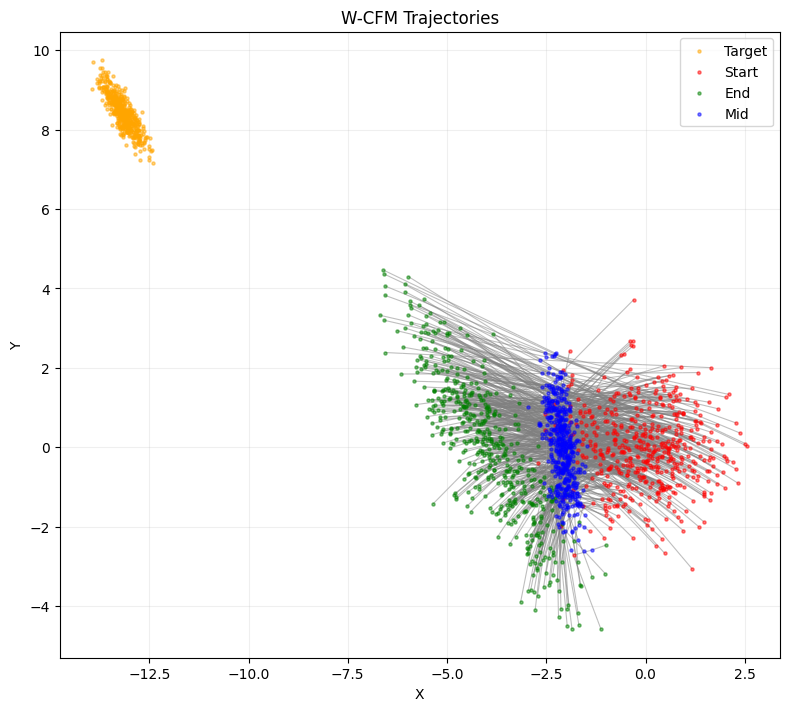

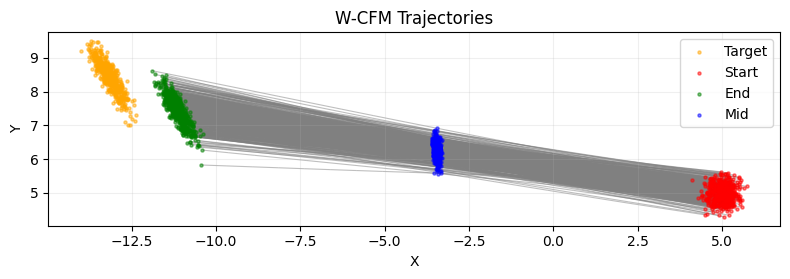

In [25]:
flow_model_mu.eval()
with torch.no_grad():
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
    n_samples = 500
    n_timesteps = 20
    time = torch.linspace(0, 1, n_timesteps)
    x_init, _ = current_coupling_dist.coupling_sample(n_samples)
    x_init = x_init.to(device)
    x_init_extended = torch.cat([x_init, x_init], dim=1)
    traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
    target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories")
    fig = plt.gcf()
    for ax in fig.axes:
        ax.set_aspect("equal", adjustable="box")
        ax.autoscale(False)

    plt.tight_layout()
    plt.show()

flow_model_mu.eval()
with torch.no_grad():
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
    n_samples = 500
    n_timesteps = 20
    time = torch.linspace(0, 1, n_timesteps)
    x_init, _ = new_source_dist.sample(n_samples), None
    x_init = x_init.to(device)
    x_init_extended = torch.cat([x_init, x_init], dim=1)
    traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
    target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories")
    fig = plt.gcf()
    for ax in fig.axes:
        ax.set_aspect("equal", adjustable="box")
        ax.autoscale(False)

    plt.tight_layout()
    plt.show()

In [26]:
import copy

initial_model_mu = MLP(dim=4, out_dim=4, w=16, time_varying=True)
initial_model_mu.load_state_dict(flow_model_mu.state_dict())
initial_model_nu = MLP(dim=4, out_dim=4, w=16, time_varying=True)
initial_model_nu.load_state_dict(flow_model_nu.state_dict())

<All keys matched successfully>

In [27]:
# # Print first layer of initial model
# first_layer_weights = initial_model.net[0].weight.data.cpu().numpy()
# print("First layer weights of the initial model:")
# print(first_layer_weights[:4])

## Learn weights

In [28]:
import copy
from dualwcfm.distributions.distribution import Distribution, FixedSizeDistribution

mode = "weight"

# weight, implicit, explicit

tau = 0.05       # Polyak averaging rate (Soft update)
gp_lambda = 0.1  # Gradient penalty weight for f and g
max_weight = 10.0

batch_size = 4096*2

mu_dist, nu_dist = current_coupling_dist.get_marginals()
mu_dist = FixedSizeDistribution(mu_dist, size=dataset_size)
nu_dist = FixedSizeDistribution(nu_dist, size=dataset_size)

def soft_update(target_net, source_net, tau):
    for target_param, source_param in zip(target_net.parameters(), source_net.parameters()):
        target_param.data.copy_(target_param.data * (1.0 - tau) + source_param.data * tau)

# flow_model = copy.deepcopy(initial_model)
# flow_model.to(device)
# previous_flow_model = copy.deepcopy(flow_model)
# previous_flow_model.eval()
# previous_flow_model = MLP(dim=4, out_dim=4, w=16, time_varying=True)
# cfm_optimizer = optim.Adam(flow_model.parameters(), lr=5e-3)


In [ ]:
import time
import numpy as np

mse_errors = {"mse": [], "min": [], "max": []}

main_start = time.perf_counter()
step_times = []

# ==============================
# Fixed evaluation batch (for stable MSE curves)
# ==============================
eval_N = batch_size
eval_idx = torch.randperm(dataset_size)[:batch_size].cpu()

for step in range(n_iterations):
    step_start = time.perf_counter()

    t_current = step * delta
    t = torch.full((batch_size, 1), t_current).to(device)

    print(f"\n=== Step {step+1}/{n_iterations} (t_current={t_current:.4f}) ===")

    # copy current flow -> previous (for implicit mode)
    previous_flow_model_mu.load_state_dict(flow_model_mu.state_dict())
    previous_flow_model_nu.load_state_dict(flow_model_nu.state_dict())
    previous_flow_model_mu.to(device); previous_flow_model_nu.to(device)
    previous_flow_model_mu.eval(); previous_flow_model_nu.eval()

    # -------------------------
    # 1) Train dual potentials f,g
    # -------------------------
    f_net.train()
    g_net.train()

    for _ in range(epochs_dual_per_step):
        x, y = current_coupling_dist.coupling_sample(batch_size)
        x_mu = mu_dist.sample(batch_size).to(device)
        y_nu = nu_dist.sample(batch_size).to(device)
        x, y = x.to(device), y.to(device)

        with torch.no_grad():
            u_t = flow_mu(torch.cat([x_mu, t], dim=1))
            v_t = flow_nu(torch.cat([y_nu, t], dim=1))

        x.requires_grad_(True)
        y.requires_grad_(True)
        x_mu.requires_grad_(True)
        y_nu.requires_grad_(True)

        a = f_net(x)
        b = g_net(y)
        a_mu = f_net(x_mu)
        b_nu = g_net(y_nu)

        term_coupling = torch.mean((a+b)**2)

        grad_a = torch.autograd.grad(a_mu.sum(), x_mu, create_graph=True, retain_graph=True, only_inputs=True)[0]
        grad_b = torch.autograd.grad(b_nu.sum(), y_nu, create_graph=True, retain_graph=True, only_inputs=True)[0]

        term_flow_a = torch.mean(torch.sum(grad_a * u_t, dim=1))
        term_flow_b = torch.mean(torch.sum(grad_b * v_t, dim=1))

        term_reg = 1e-3 * (torch.mean(a**2) + torch.mean(b**2)) + 1e-3 * (torch.mean(a_mu**2) + torch.mean(b_nu**2))

        gp_f = ((grad_a.norm(2, dim=1) - 1) ** 2).mean()
        gp_g = ((grad_b.norm(2, dim=1) - 1) ** 2).mean()

        loss_dual = 0.5 * term_coupling - term_flow_a - term_flow_b + term_reg + gp_lambda * (gp_f + gp_g)

        optimizer_dual.zero_grad()
        loss_dual.backward()
        optimizer_dual.step()

    # -------------------------
    # 2) Train weighted-CFM (flow_model_mu / flow_model_nu)
    # -------------------------
    flow_model_mu.train()
    flow_model_nu.train()
    f_net.eval()
    g_net.eval()
    for epoch in range(epochs_cfm_per_step):
        x0, x1 = current_coupling_dist.coupling_sample(batch_size)
        x0, x1 = x0.to(device), x1.to(device)
        s = torch.rand(batch_size, 1).to(device)

        dim = x0.shape[1]  # safer than hard-coding 2

        if step % 2 == 0:
            # mu-branch: x0 -> x1
            xs = interpolate(x0, x1, s, sigma)
            u_s_full = flow_model_mu(torch.cat([xs, x0, s], dim=1))   # (B,2d)
            u_s = u_s_full[:, :dim]
        else:
            # nu-branch: x1 -> x0
            xs = interpolate(x1, x0, s, sigma)
            u_s_full = flow_model_nu(torch.cat([xs, x1, s], dim=1))   # (B,2d)
            u_s = u_s_full[:, :dim]

        with torch.no_grad():
            a, b = f_net(x0), g_net(x1)        # (B,1),(B,1)
            r = a + b                          # (B,1)
            weight = torch.exp(r * delta)      # (B,1)

        if mode == "weight":
            target = (x1 - x0) if step % 2 == 0 else (x0 - x1)        # (B,d)
            full_target = torch.cat([target, torch.zeros_like(x0)], dim=1)  # (B,2d)
            # normalize optional; keep your original style if you want
            loss_cfm = (weight * (u_s_full - full_target) ** 2).mean()

        elif mode == "implicit":
            with torch.no_grad():
                b_hat_detached = u_s.detach()  # (B,d)

                if step % 2 == 0:
                    b_ta = previous_flow_model_mu(torch.cat([xs, x0, s], dim=1))[:, :dim]  # (B,d)
                    target = (x1 - x0)
                else:
                    b_ta = previous_flow_model_nu(torch.cat([xs, x1, s], dim=1))[:, :dim]  # (B,d)
                    target = (x0 - x1)

                itm_target = b_ta + (weight - 1.0) * (target - b_hat_detached)  # (B,d)
                full_target = torch.cat([itm_target, torch.zeros_like(x0)], dim=1)  # (B,2d)

            loss_cfm = nn.functional.mse_loss(u_s_full, full_target)

        elif mode == "explicit":
            with torch.no_grad():
                if step % 2 == 0:
                    # mu-branch: x0 -> x1
                    b_ta = previous_flow_model_mu(torch.cat([xs, x0, s], dim=1))[:, :dim]  # (B,d)
                    target = (x1 - x0)  # (B,d)
                else:
                    # nu-branch: x1 -> x0
                    b_ta = previous_flow_model_nu(torch.cat([xs, x1, s], dim=1))[:, :dim]  # (B,d)
                    target = (x0 - x1)  # (B,d)

                # # explicit Euler target: b_next = b_ta + delta * r * (target - b_ta)
                # alpha = delta * r
                # alpha = torch.clamp(alpha, -0.5, 0.5)   # 先用0.5，很稳；想快可调到1.0
                # schrodinger_target = b_ta + alpha * (target - b_ta)

                schrodinger_target = b_ta + delta * (r * (target - b_ta))   # (B,d)


                full_target = torch.cat([schrodinger_target, torch.zeros_like(x0)], dim=1)  # (B,2d)

            loss_cfm = nn.functional.mse_loss(u_s_full, full_target)

        else:
            raise ValueError(f"Unknown mode: {mode}")

        # --- optimizer step: update only the active branch ---
        if step % 2 == 0:
            cfm_optimizer_mu.zero_grad()
            loss_cfm.backward()
            cfm_optimizer_mu.step()
        else:
            cfm_optimizer_nu.zero_grad()
            loss_cfm.backward()
            cfm_optimizer_nu.step()

    # -------------------------
    # 3) (Optional) step-level diagnostics (NO PLOTS, only scalar prints)
    # -------------------------
    if step % 2 == 0:
        with torch.no_grad():
            A_dev = A_const.to(device)
            b_dev = b_const.to(device)

            # take the SAME samples every time
            x = current_coupling_dist.dataset[0, eval_idx].to(device)
            y = current_coupling_dist.dataset[1, eval_idx].to(device)

            y_theory = x @ A_dev.T + b_dev

            map_err = torch.sum((y - y_theory) ** 2, dim=1)

            map_mse = map_err.mean().item()
            map_var = map_err.var(unbiased=False).item()
            map_min = map_err.min().item()
            map_max = map_err.max().item()

        print(f"[Step {step}] Map MSE = {map_mse:.6f}  var={map_var:.6f}")
        print(f"[Step {step}] min={map_min:.6f}, max={map_max:.6f}")

        # with torch.no_grad():
        #     x_ref, y_ref = current_coupling_dist.coupling_sample(batch_size)
        #     x_ref, y_ref = x_ref.to(device), y_ref.to(device)

        #     # ✅ IMPORTANT: some coupling_sample implementations return <= requested size
        #     N = min(x_ref.shape[0], y_ref.shape[0])
        #     x_ref = x_ref[:N]
        #     y_ref = y_ref[:N]

        #     # theoretical coupled target: y = A x + b
        #     A_dev = A.to(device)
        #     b_dev = b.to(device)
        #     y_theory = x_ref @ A_dev.T + b_dev  # (N,2)

        #     # per-sample squared error (sum over dims)
        #     per_point = torch.sum((y_ref - y_theory) ** 2, dim=1)  # (N,)
        #     map_mse = per_point.mean().item()
        #     map_min = per_point.min().item()
        #     map_max = per_point.max().item()


        # print(f"[Step {step}] Map MSE E||y-(Ax+b)||^2: {map_mse:.6f} (min={map_min:.6f}, max={map_max:.6f})")
        # print(f"[Step {step}] Midpoint norm: mean={mid_mean:.6f}, var={mid_var:.6f}")

        # mse_errors["mse"].append(map_mse)
        # mse_errors["min"].append(map_min)
        # mse_errors["max"].append(map_max)  # ✅ FIXED indentation: inside the if

    # -------------------------
    # 4) Advance the dataset (unchanged, but remove inner trange for speed)
    # -------------------------
    chunks = 100_000
    num_steps = 50
    dt = 1.0 / num_steps
    flow_mu.eval()
    flow_nu.eval()

    with torch.no_grad():
        for i in range(0, dataset_size, chunks):
            x_mu = mu_dist.dataset[i:i+chunks].to(device)
            y_nu = nu_dist.dataset[i:i+chunks].to(device)

            t_tensor = torch.full((x_mu.shape[0], 1), t_current).to(device)

            x_mu_next = x_mu + delta * flow_mu(torch.cat([x_mu, t_tensor], dim=1))
            y_nu_next = y_nu + delta * flow_nu(torch.cat([y_nu, t_tensor], dim=1))

            if step % 2 == 0:
                x_next = x_mu_next.detach().clone()
                xt = x_next.clone()
                for j in range(num_steps):
                    tj = torch.ones(x_next.shape[0], 1).to(device) * (j * dt)
                    vt = flow_model_mu(torch.cat([xt, x_next, tj], dim=1))[:, :2]
                    xt = xt + vt * dt
                y_next = xt.clone()
            else:
                y_next = y_nu_next.detach().clone()
                yt = y_next.clone()
                for j in range(num_steps):
                    tj = torch.ones(y_next.shape[0], 1).to(device) * (j * dt)
                    vt = flow_model_nu(torch.cat([yt, y_next, tj], dim=1))[:, :2]
                    yt = yt + vt * dt
                x_next = yt.clone()

            # write back to CPU datasets
            current_coupling_dist.dataset[:, i:i+chunks] = torch.stack([x_next.cpu(), y_next.cpu()], dim=0)
            mu_dist.dataset[i:i+chunks] = x_mu_next.cpu()
            nu_dist.dataset[i:i+chunks] = y_nu_next.cpu()

    # step timing
    step_end = time.perf_counter()
    step_times.append(step_end - step_start)
    print(f"[Step {step+1}/{n_iterations}] done. step_time={step_times[-1]:.2f}s, total_elapsed={step_end-main_start:.2f}s")

# total timing summary
total = time.perf_counter() - main_start
print(f"\n=== Main loop finished ===")
print(f"Total time: {total:.2f}s")
print(f"Avg time/step: {np.mean(step_times):.2f}s (min={np.min(step_times):.2f}s, max={np.max(step_times):.2f}s)")



=== Step 1/50 (t_current=0.0000) ===
[Step 0] Map MSE = 0.000000  var=0.000000
[Step 0] min=0.000000, max=0.000000
[Step 1/50] done. step_time=7.23s, total_elapsed=7.24s

=== Step 2/50 (t_current=0.0200) ===
[Step 2/50] done. step_time=8.88s, total_elapsed=16.12s

=== Step 3/50 (t_current=0.0400) ===
[Step 2] Map MSE = 0.000142  var=0.000000
[Step 2] min=0.000000, max=0.014706
[Step 3/50] done. step_time=8.73s, total_elapsed=24.85s

=== Step 4/50 (t_current=0.0600) ===
[Step 4/50] done. step_time=10.87s, total_elapsed=35.71s

=== Step 5/50 (t_current=0.0800) ===
[Step 4] Map MSE = 0.000187  var=0.000001
[Step 4] min=0.000000, max=0.033669
[Step 5/50] done. step_time=8.11s, total_elapsed=43.82s

=== Step 6/50 (t_current=0.1000) ===
[Step 6/50] done. step_time=8.10s, total_elapsed=51.92s

=== Step 7/50 (t_current=0.1200) ===
[Step 6] Map MSE = 0.005224  var=0.000006
[Step 6] min=0.000065, max=0.065108
[Step 7/50] done. step_time=8.90s, total_elapsed=60.82s

=== Step 8/50 (t_current=0.14

In [30]:
# import copy
# from dualwcfm.distributions.distribution import Distribution, FixedSizeDistribution

# mode = "weight"

# # weight, implicit, explicit

# tau = 0.05       # Polyak averaging rate (Soft update)
# gp_lambda = 0.1  # Gradient penalty weight for f and g
# max_weight = 10.0

# batch_size = 4096*2

# mu_dist, nu_dist = current_coupling_dist.get_marginals()
# mu_dist = FixedSizeDistribution(mu_dist, size=dataset_size)
# nu_dist = FixedSizeDistribution(nu_dist, size=dataset_size)

# def soft_update(target_net, source_net, tau):
#     for target_param, source_param in zip(target_net.parameters(), source_net.parameters()):
#         target_param.data.copy_(target_param.data * (1.0 - tau) + source_param.data * tau)

# # flow_model = copy.deepcopy(initial_model)
# # flow_model.to(device)
# # previous_flow_model = copy.deepcopy(flow_model)
# # previous_flow_model.eval()
# # previous_flow_model = MLP(dim=4, out_dim=4, w=16, time_varying=True)
# # cfm_optimizer = optim.Adam(flow_model.parameters(), lr=5e-3)

# mse_errors = {"mse": [], "min": [], "max": []}
# # n_iterations = 500
# for step in range(n_iterations):
#     t_current = step * delta
#     t = torch.full((batch_size, 1), t_current).to(device)

#     # previous_flow_model.load_state_dict(flow_model.state_dict())
#     # previous_flow_model.to(device)
#     # previous_flow_model.eval()

#     previous_flow_model_mu.load_state_dict(flow_model_mu.state_dict())
#     previous_flow_model_nu.load_state_dict(flow_model_nu.state_dict())
#     previous_flow_model_mu.to(device)
#     previous_flow_model_nu.to(device)
#     previous_flow_model_mu.eval()
#     previous_flow_model_nu.eval()

#     f_net.train()
#     g_net.train()

#     pbar = trange(epochs_dual_per_step)
#     for _ in pbar:
#         x, y = current_coupling_dist.coupling_sample(batch_size)
#         x_mu, y_nu = mu_dist.sample(batch_size).to(device), nu_dist.sample(batch_size).to(device)

#         x, y = x.to(device), y.to(device)

#         with torch.no_grad():
#             u_t = flow_mu(torch.cat([x_mu, t], dim=1))
#             v_t = flow_nu(torch.cat([y_nu, t], dim=1))

#         x.requires_grad_(True)
#         y.requires_grad_(True)
#         x_mu.requires_grad_(True)
#         y_nu.requires_grad_(True)

#         a = f_net(x)#torch.cat([x, t], dim=1))
#         b = g_net(y)#torch.cat([y, t], dim=1))
#         a_mu = f_net(x_mu)
#         b_nu = g_net(y_nu)

#         # Loss computation (Variational)
#         term_coupling = torch.mean((a - a.mean() + b - b.mean())**2)

#         # Divergence terms
#         grad_a = torch.autograd.grad(a_mu.sum(), x_mu, create_graph=True, retain_graph=True, only_inputs=True)[0]
#         grad_b = torch.autograd.grad(b_nu.sum(), y_nu, create_graph=True, retain_graph=True, only_inputs=True)[0]

#         term_flow_a = torch.mean(torch.sum(grad_a * u_t, dim=1))
#         term_flow_b = torch.mean(torch.sum(grad_b * v_t, dim=1))

#         # L2 Regularization
#         term_reg = 1e-3 * (torch.mean(a**2) + torch.mean(b**2)) + 1e-3 * (torch.mean(a_mu**2) + torch.mean(b_nu**2))

#         # Lipschitz Constraint
#         gp_f = ((grad_a.norm(2, dim=1) - 1) ** 2).mean()
#         gp_g = ((grad_b.norm(2, dim=1) - 1) ** 2).mean()

#         loss = 0.5 * term_coupling - term_flow_a - term_flow_b + term_reg + gp_lambda * (gp_f + gp_g)

#         optimizer_dual.zero_grad()
#         loss.backward()
#         optimizer_dual.step()

#         pbar.set_description(f"Dual Loss: {loss.item():.4f}")

#     # Plot a heatmap of a_t(x) + b_t(y) on the current coupling
#     # if step > 0 and step % 5 == 0:
#     #     x, y = mu_dist.sample(1000).to(device), nu_dist.sample(1000).to(device)
#     #     true_a = -1/t_current + 2/t_current**2 * (x - 5*t_current)**2 + 20/t_current * (x[:, 0] + x[:, 1] - 10*t_current)
#     #     true_b = -1/t_current + 2/t_current**2 * (y + 5*(1 - t_current))**2 - 20/t_current * (y[:, 0] + y[:, 1] + 10*t_current)

#     #     with torch.no_grad():
#     #         a = f_net(x).view(-1)
#     #         b = g_net(y).view(-1)

#     #         log_weights = (a + b) * delta
#     #         true_log_weights = (true_a + true_b) * delta

#     #         mse = nn.functional.mse_loss(log_weights, true_log_weights).item()
#     #         print(f"Step {step}: MSE between learned and true log-weights: {mse:.6f}")

#     # 3. Learn weighted-CFM at next step
#     # flow_model.train()
#     flow_model_mu.train()
#     flow_model_nu.train()
#     f_net.eval()
#     g_net.eval()

#     # cfm_scheduler = optim.lr_scheduler.CosineAnnealingLR(cfm_optimizer, T_max=epochs_cfm_per_step)

#     pbar = trange(epochs_cfm_per_step)
#     for epoch in pbar:
#         x0, x1 = current_coupling_dist.coupling_sample(batch_size)
#         x0, x1 = x0.to(device), x1.to(device)

#         s = torch.rand(batch_size, 1).to(device)

#         # u_s = flow_model(torch.cat([xs, x0, s], dim=1))
#         if step % 2 == 0:
#             xs = interpolate(x0, x1, s, sigma)
#             u_s_full = flow_model_mu(torch.cat([xs, x0, s], dim=1))
#             u_s = u_s_full[:, :2]
#         else:
#             xs = interpolate(x1, x0, s, sigma)
#             u_s_full = flow_model_nu(torch.cat([xs, x1, s], dim=1))
#             u_s = u_s_full[:, :2]

#         with torch.no_grad():
#             a, b = f_net(x0), g_net(x1)#torch.cat([x0, t], dim=1)), g_net(torch.cat([x1, t], dim=1)) # Not the same t
#             r = a + b
#             log_w = r * delta
#             # log_w = log_w - torch.median(log_w)
#             # weight = torch.exp(torch.clamp(log_w, max=5.0))
#             weight = torch.exp(log_w)
#             # log_w = log_w - log_w.max()
#             # weight = torch.exp(log_w)
#             # weight = weight / (weight.mean() + 1e-8)
#             # weight = torch.clamp(weight, max=50.0)

#             # stop_grad_u_s = flow_model(torch.cat([xs, x0, s], dim=1)).detach()
#         if mode == "weight":
#             schrodinger_u_s = (x1 - x0) if step % 2 == 0 else (x0 - x1)
#             #+ (1 - 2*s) / (2 * t *(1 - t) + 1e-8) * (x - (t  * x1 + (1 - t) * x0))
#             target_u_s = torch.cat([schrodinger_u_s, torch.zeros_like(x0)], dim=1)
#             loss = (weight * (u_s_full - target_u_s)**2).mean()
#         elif mode == "implicit":
#             # raise NotImplementedError("Implicit mode not implemented yet.")
#             with torch.no_grad():
#                 b_hat_detached = u_s.detach()
#                 if step % 2 == 0:
#                     b_ta = previous_flow_model_mu(torch.cat([xs, x0, s], dim=1))[:, :2]
#                     target = x1 - x0
#                 else:
#                     b_ta = previous_flow_model_nu(torch.cat([xs, x1, s], dim=1))[:, :2]
#                     target = x0 - x1

#                 # ITM Residual: T_ITM = b_ta + (exp(hr) - 1) * (dot_I - b_hat)
#                 itm_target = b_ta + (weight - 1.0) * (target - b_hat_detached)
#                 full_target = torch.cat([itm_target, torch.zeros_like(x0)], dim=1)

#             # loss = nn.functional.mse_loss(u_s, itm_target)
#             loss = nn.functional.mse_loss(u_s_full, full_target)
#         elif mode == "explicit":
#             with torch.no_grad():
#                 prev_val = previous_flow_model_mu(torch.cat([xs, x0, s], dim=1)).detach()[:, :2]
#                 residual = (x1 - x0) * r - prev_val * r
#                 schrodinger_target = prev_val + delta * residual
#             schrodinger_target = torch.cat([schrodinger_target, torch.zeros_like(x0)], dim=1)
#             loss = ((u_s - schrodinger_target)**2).mean()
#         # Derivative of (1-t)x0 + t x1 + sigma*sqrt(t(1-t))eps
#         # flow_true = torch.cat([x1 - x0, torch.zeros_like(x0)], dim=1)
#         # target_u_s = flow_true + (weight - 1.0) * (flow_true - stop_grad_u_s)

#         # loss = torch.mean(weight * (u_s - target_u_s)**2)
#         # loss = torch.mean(weight * torch.sum((u_s - target_u_s)**2, dim=1, keepdim=True))

#         # cfm_optimizer.zero_grad()
#         # loss.backward()
#         # cfm_optimizer.step()
#         cfm_optimizer_mu.zero_grad()
#         cfm_optimizer_nu.zero_grad()
#         loss.backward()
#         cfm_optimizer_mu.step()
#         cfm_optimizer_nu.step()
#         # cfm_scheduler.step()

#         # if mode == "implicit":
#         #     soft_update(previous_flow_model, flow_model, tau)

#         pbar.set_description(f"CFM Loss: {loss.item():.4f}")

#     if step % 2 == 0:
#         x_ref, y_ref = current_coupling_dist.coupling_sample(10000)
#         x_ref, y_ref = x_ref.to(device), y_ref.to(device)
#         plot_iteration_diagnostics(step, x_ref, y_ref, f_net, g_net, flow_model_mu, device)

#         # Print actual error between current coupling and optimal coupling that uses anticorrelate function
#         with torch.no_grad():
#             loss = (y_ref + x_ref)**2
#             error = torch.mean(loss).item()
#             print(f"Step {step}: MSE {error:.4f} (min: {loss.min().item():.4f}, max: {loss.max().item():.4f})")
#         mse_errors["mse"].append(error)
#         mse_errors["min"].append(loss.min().item())
#         mse_errors["max"].append(loss.max().item())

#         # first_layer_weights = flow_model.net[0].weight.data.cpu().numpy()
#         # print("First layer weights of the initial model:")
#         # print(first_layer_weights[:4])

#         # 4. Visualize learned W-CFM at current step
#         flow_model_mu.eval()
#         with torch.no_grad():
#             cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
#             n_samples = 500
#             n_timesteps = 50
#             time = torch.linspace(0, 1, n_timesteps)
#             # x_init = new_source_dist.sample(n_samples).to(device)
#             # x_init = source_dist.sample(n_samples).to(device)
#             x_init, _ = current_coupling_dist.coupling_sample(n_samples)
#             x_init = x_init.to(device)
#             x_init_extended = torch.cat([x_init, x_init], dim=1)
#             traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
#             target_samples = new_target_dist.sample(n_samples).cpu().numpy()

#             plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")
#             plt.show()

#     chunks = 100_000
#     num_steps = 50
#     dt = 1.0 / num_steps
#     flow_mu.eval()
#     flow_nu.eval()
#     cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
#     with torch.no_grad():
#         for i in trange(0, dataset_size, chunks):
#             samples = current_coupling_dist.dataset[:, i:i+chunks]
#             # x, y = samples[0].to(device), samples[1].to(device)
#             x_mu, y_nu = mu_dist.dataset[i:i+chunks].to(device), nu_dist.dataset[i:i+chunks].to(device)

#             t_tensor = torch.full((x_mu.shape[0], 1), t_current).to(device)

#             x_mu_next = x_mu.detach() + delta * flow_mu(torch.cat([x_mu, t_tensor], dim=1))
#             y_nu_next = y_nu.detach() + delta * flow_nu(torch.cat([y_nu, t_tensor], dim=1))

#             if step % 2 == 0:
#                 # x_next = x.detach() + delta * flow_mu(torch.cat([x, t_tensor], dim=1))
#                 x_next = x_mu_next.detach().clone()

#                 xt = x_next.clone()
#                 for j in range(num_steps):
#                     t = torch.ones(x_next.shape[0], 1).to(device) * (j * dt)
#                     vt = flow_model_mu(torch.cat([xt, x_next, t], dim=1))[:, :2]
#                     xt = xt + vt * dt
#                 y_next = xt.clone()
#             else:
#                 # y_next = y.detach() + delta * flow_nu(torch.cat([y, t_tensor], dim=1))
#                 y_next = y_nu_next.detach().clone()

#                 yt = y_next.clone()
#                 for j in range(num_steps):
#                     t = torch.ones(y_next.shape[0], 1).to(device) * (j * dt)
#                     vt = flow_model_nu(torch.cat([yt, y_next, t], dim=1))[:, :2]
#                     yt = yt + vt * dt
#                 x_next = yt.clone()


#             # 2. Advance y (Target Marginal) by delta
#             # Evaluate flow_model at t=1 (the target end)

#             # We use the coupled velocity b_t,a+h(y, x_next, 1)
#             # to move y into the next tilted marginal
#             # k1_v = flow_model(torch.cat([y, x_next, s_one], dim=1))[:, :2]
#             # mid_y = y + 0.5 * delta * k1_v
#             # y_next = y + delta * flow_model(torch.cat([mid_y, x_next, s_one], dim=1))[:, :2]
#             # t_one = torch.ones(x.shape[0], 1).to(device)
#             # y_next = y.detach() + delta * flow_model(torch.cat([y, x_next, t_one], dim=1))[:, :2]

#             # x_next = x.detach() + delta * flow_mu(torch.cat([x, t_tensor], dim=1))
#             # xt = x_next.clone()
#             # for step_idx in range(num_steps):
#             #     s = torch.full((x.shape[0], 1), step_idx / num_steps).to(device)
#             #     # We use the updated x as the conditioning 'x0' to maintain
#             #     # the Schrödinger Bridge coupling for the next tilt step.
#             #     k1 = flow_model(torch.cat([xt, x, s], dim=1))[:, :2]
#             #     mid_xt = xt + 0.5 * dt * k1
#             #     k2 = flow_model(torch.cat([mid_xt, x, s + (0.5 * dt / delta)], dim=1))[:, :2]
#             #     xt = xt + dt * k2

#             # y_next = xt
#             # u_t = flow_mu(torch.cat([x, t_tensor], dim=1))

#             # x_next = x.detach() + delta * u_t

#             # x_init = torch.cat([x_next, x_next], dim=1)
#             # traj = cfm.get_trajectory(x0=x_init, n_timesteps=num_steps)
#             # y_next = traj[-1, :, :2]

#             # Detach to free graph for next step
#             x_next = x_next.detach().cpu()
#             y_next = y_next.detach().cpu()

#             current_coupling_dist.dataset[:, i:i+chunks] = torch.stack([x_next, y_next], dim=0)
#             mu_dist.dataset[i:i+chunks] = x_mu_next
#             nu_dist.dataset[i:i+chunks] = y_nu_next

# flow_model_mu.eval()
# with torch.no_grad():
#     cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
#     n_samples = 50
#     n_timesteps = 20
#     time = torch.linspace(0, 1, n_timesteps)
#     x_init = new_source_dist.sample(n_samples).to(device)
#     # x_init = new_source_dist.sample(n_samples).to(device)
#     x_init_extended = torch.cat([x_init, x_init], dim=1)
#     traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
#     # traj = cfm.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
#     target_samples = new_target_dist.sample(n_samples).cpu().numpy()

#     plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")
#     plt.show()

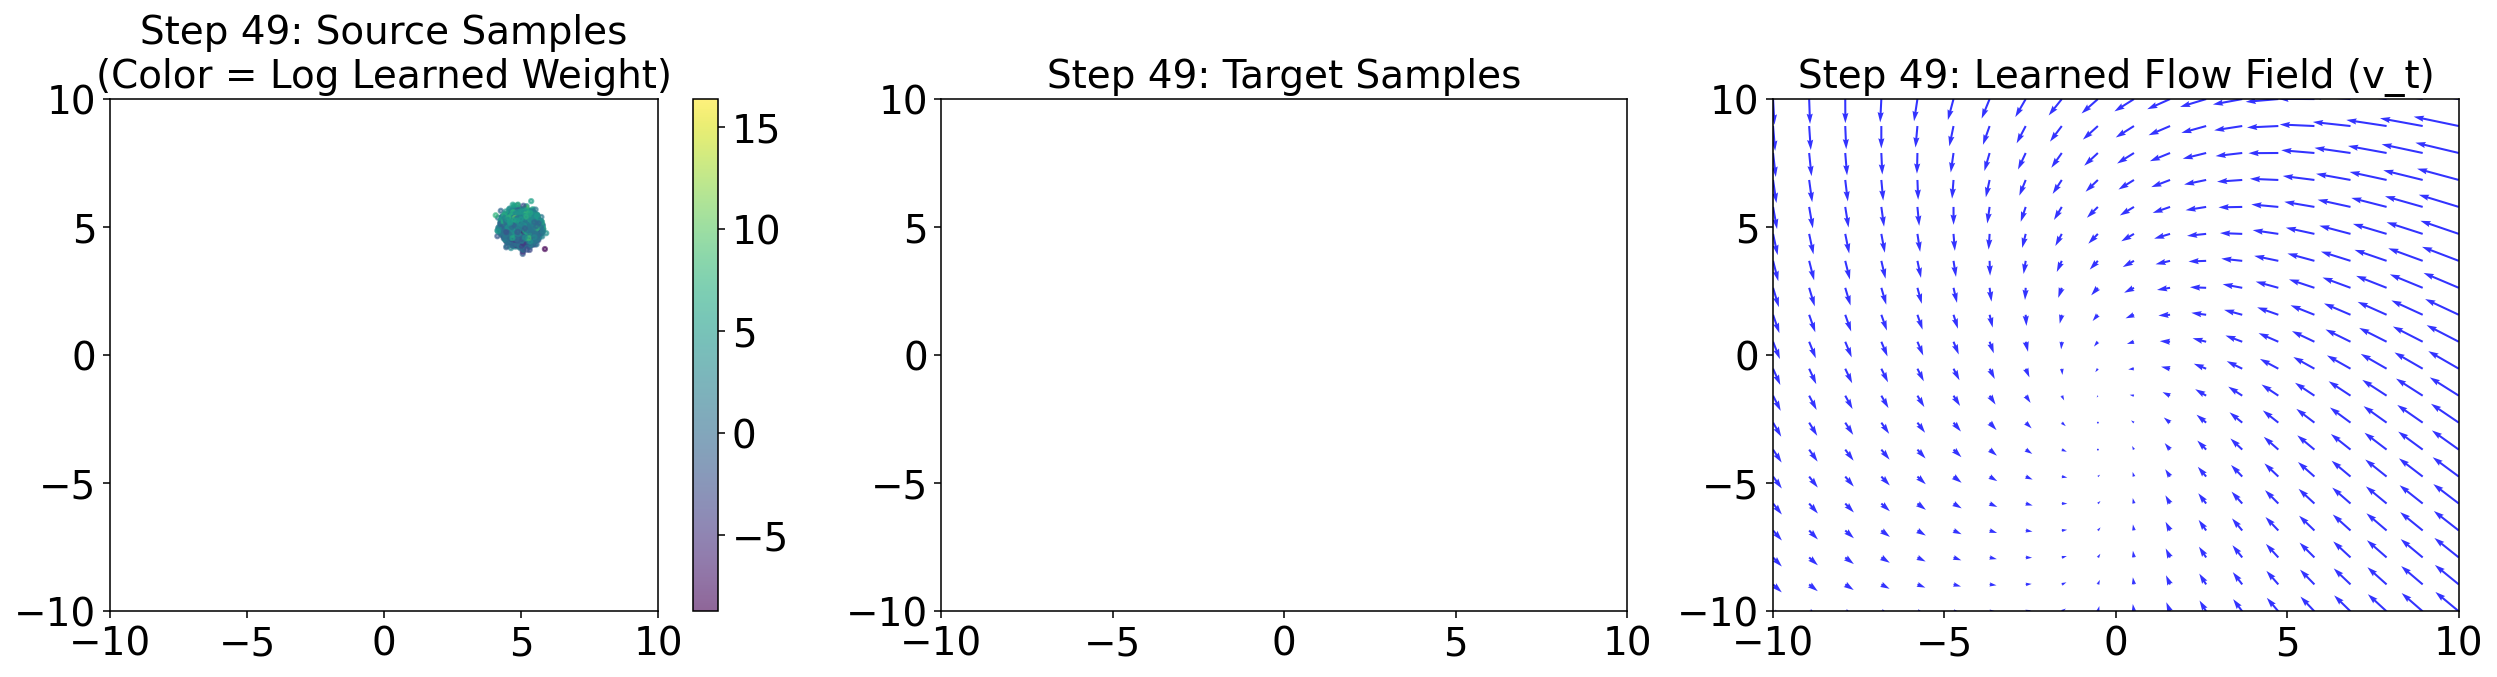

torch.Size([50, 500, 4])
Mean of y in x dimension: -13.120360374450684, Mean of y in y dimension: 8.324721336364746
Mean of y in x dimension: -13.164714813232422, Mean of y in y dimension: 8.403534889221191
Mean of new source in x dimension: 4.994274616241455, Mean of y in y dimension: 4.996675491333008


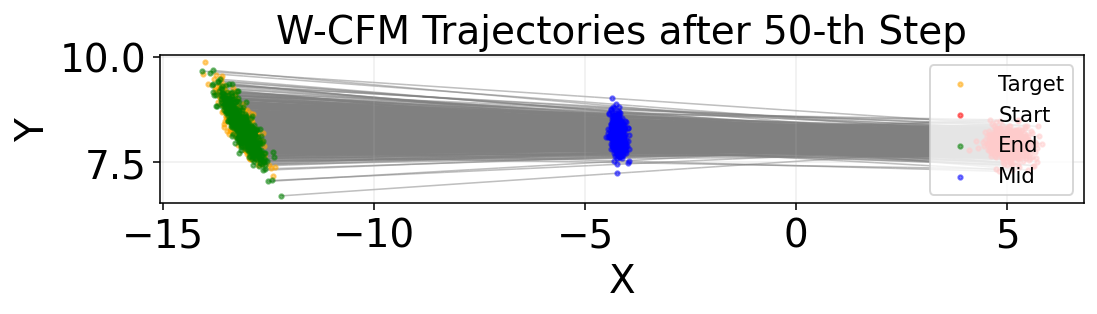

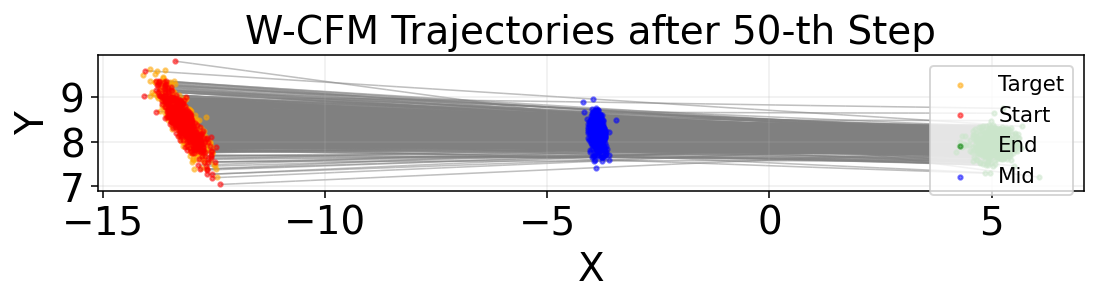

In [39]:
x_ref, y_ref = current_coupling_dist.coupling_sample(10000)
x_ref = new_source_dist.sample(10000)
x_ref, y_ref = x_ref.to(device), y_ref.to(device)
plot_iteration_diagnostics(step, x_ref, y_ref, f_net, g_net, flow_model_mu, device)

# 4. Visualize learned W-CFM at current step
flow_model_mu.eval()
with torch.no_grad():
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_mu, sigma=0)
    n_samples = 500
    n_timesteps = 50
    time = torch.linspace(0, 1, n_timesteps)
    # x_init = new_source_dist.sample(n_samples).to(device)
    # x_init = source_dist.sample(n_samples).to(device)
    x_init, _ = current_coupling_dist.coupling_sample(n_samples)
    x_init = x_init.to(device)
    x_init_extended = torch.cat([x_init, x_init], dim=1)
    traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
    target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    print(traj.shape)
    print(f"Mean of y in x dimension: {traj[-1, :, 0].mean().item()}, Mean of y in y dimension: {traj[-1, :, 1].mean().item()}")
    print(f"Mean of y in x dimension: {target_samples[:, 0].mean().item()}, Mean of y in y dimension: {target_samples[:, 1].mean().item()}")
    print(f"Mean of new source in x dimension: {x_ref[:, 0].mean().item()}, Mean of y in y dimension: {x_ref[:, 1].mean().item()}")


    plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")
    fig = plt.gcf()
    for ax in fig.axes:
        # ax.set_xlim(-13, 13)
        # ax.set_ylim(-13, 13)
        ax.set_aspect("equal", adjustable="box")
        ax.autoscale(False)

    plt.tight_layout()
    plt.show()

flow_model_nu.eval()
with torch.no_grad():
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model_nu, sigma=0)
    n_samples = 500
    n_timesteps = 50
    time = torch.linspace(0, 1, n_timesteps)
    # x_init = new_source_dist.sample(n_samples).to(device)
    # x_init = source_dist.sample(n_samples).to(device)
    _, x_init = current_coupling_dist.coupling_sample(n_samples)
    x_init = x_init.to(device)
    x_init_extended = torch.cat([x_init, x_init], dim=1)
    traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
    target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")
    fig = plt.gcf()
    for ax in fig.axes:
        # ax.set_xlim(-13, 6)
        # ax.set_ylim(2, 13)
        ax.set_aspect("equal", adjustable="box")
        ax.autoscale(False)

    plt.tight_layout()
    plt.show()

# 4. Visualize learned W-CFM at current step
# flow_model_mu.eval()
# with torch.no_grad():
#     cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, initial_model, sigma=0)
#     n_samples = 500
#     n_timesteps = 50
#     time = torch.linspace(0, 1, n_timesteps)
#     # x_init = new_source_dist.sample(n_samples).to(device)
#     # x_init = source_dist.sample(n_samples).to(device)
#     x_init, _ = current_coupling_dist.coupling_sample(n_samples)
#     x_init = x_init.to(device)
#     x_init_extended = torch.cat([x_init, x_init], dim=1)
#     traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
#     target_samples = new_target_dist.sample(n_samples).cpu().numpy()

#     plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")
#     plt.show()

In [32]:
# ---- Coupling diagnostic: learned vs theoretical linear map ----
with torch.no_grad():
    A_dev = A_const.to(device)
    b_dev = b_const.to(device)

    # align N
    N = min(x_ref.shape[0], y_ref.shape[0])
    x = x_ref[:N]
    y = y_ref[:N]

    # theoretical target
    y_theory = x @ A_dev.T + b_dev          # (N,2)

    # mapping error per sample
    map_err = torch.sum((y - y_theory) ** 2, dim=1)   # ||y - (Ax+b)||^2

    map_mse = map_err.mean().item()
    map_var = map_err.var(unbiased=False).item()
    map_min = map_err.min().item()
    map_max = map_err.max().item()

    # midpoint diagnostic (optional geometric check)
    # mid_learn = 0.5 * (x + y)
    # mid_theory = 0.5 * (x + y_theory)

    # mid_err = torch.linalg.norm(mid_learn - mid_theory, dim=1)

    # mid_mean = mid_err.mean().item()
    # mid_var  = mid_err.var(unbiased=False).item()

print(f"[Step {step}] Map MSE   E||y-(Ax+b)||^2 = {map_mse:.6f}")
print(f"[Step {step}] Map var   = {map_var:.6f}, min={map_min:.6f}, max={map_max:.6f}")
# print(f"[Step {step}] Midpoint error: mean={mid_mean:.6f}, var={mid_var:.6f}")

[Step 49] Map MSE   E||y-(Ax+b)||^2 = 3.251200
[Step 49] Map var   = 0.376381, min=1.128124, max=6.159811


In [33]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 0) Data (use yours as-is)
# =========================

# ---- Weight ----
steps_w = np.array([10, 20, 30, 40, 50, 60], dtype=float)
time_w  = np.array([18.60, 37.00, 54.79, 71.13, 88.80, 107.44], dtype=float)
mse_runs_w = {
    10: [1.584478, 0.635243, 1.308597, 1.267060, 1.030978],
    20: [1.597324, 0.638312, 0.339923, 0.781386, 0.313185],
    30: [0.067707, 0.256198, 0.217392, 0.400787, 0.639585],
    40: [0.295025, 0.153583, 0.187620, 0.114991, 0.287472],
    50: [0.202838, 0.008224, 0.066590, 0.038664, 0.107526],
    60: [0.024815, 0.112665, 0.165175, 0.185003, 0.050523],
}

# ---- Implicit ----
steps_i = np.array([10, 20, 30, 40, 50, 60], dtype=float)
time_i  = np.array([19.55, 39.52, 61.15, 79.11, 98.29, 121.44], dtype=float)
mse_runs_i = {
    10: [3.863805, 1.031221, 0.573239, 1.823102, 4.521854],
    20: [2.857449, 0.530565, 1.005322, 0.883882, 2.076830],
    30: [0.586569, 0.079634, 0.649521, 0.392419, 0.158407],
    40: [0.290636, 0.554218, 0.134345, 0.056646, 0.160250],
    50: [0.107140, 0.173114, 0.076940, 0.047794, 0.011935],
    60: [0.150006, 0.233123, 0.162628, 0.340603, 0.166879],
}

# ---- Explicit ----
steps_e = np.array([50, 60], dtype=float)
time_e  = np.array([95.05, 113.42], dtype=float)
mse_runs_e = {
    50: [0.053883, 0.053865, 0.084406, 0.035308, 0.102351],
    60: [0.011105, 0.191628, 0.099439, 0.004397, 0.257750],
}


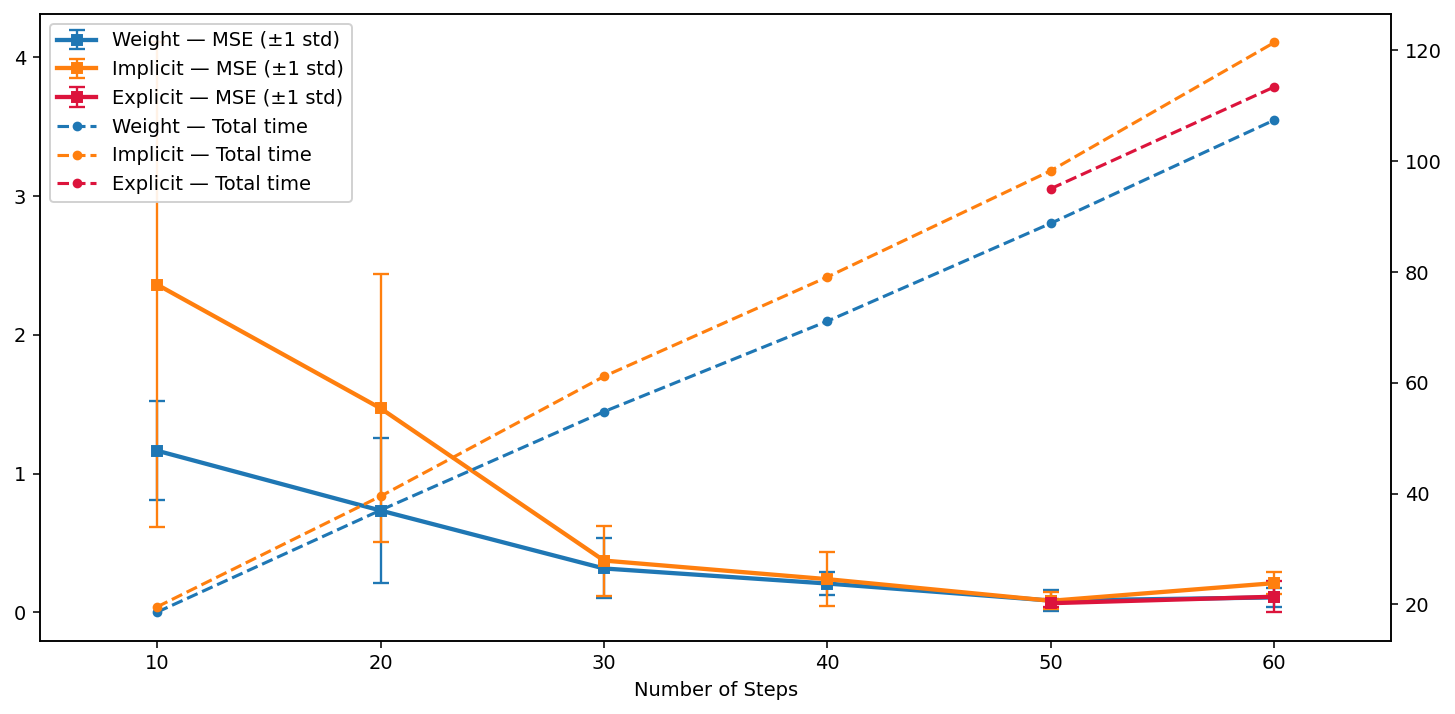

In [34]:
# =========================
# 1) Helper: mean/std from runs
# =========================
def mean_std_from_runs(steps: np.ndarray, runs_dict: dict):
    means, stds = [], []
    for s in steps.astype(int):
        vals = np.array(runs_dict[int(s)], dtype=float)
        means.append(vals.mean())
        stds.append(vals.std(ddof=1) if len(vals) > 1 else 0.0)
    return np.array(means), np.array(stds)

mse_w_mean, mse_w_std = mean_std_from_runs(steps_w, mse_runs_w)
mse_i_mean, mse_i_std = mean_std_from_runs(steps_i, mse_runs_i)
mse_e_mean, mse_e_std = mean_std_from_runs(steps_e, mse_runs_e)

# =========================
# 2) Plot: 3-method comparison in one figure
# =========================
fig, ax_left = plt.subplots(figsize=(10.5, 5.2), dpi=140)

# X ticks: union of all steps + 0
all_steps = sorted(set([0] + steps_w.astype(int).tolist() + steps_i.astype(int).tolist() + steps_e.astype(int).tolist()))
xmax = int(max(all_steps))
ax_left.set_xlim(0, xmax)
ax_left.set_xticks(all_steps)
ax_left.set_xlabel("Number of Steps")

# ---- Left axis: MSE with error bars ----
ax_left.errorbar(
    steps_w, mse_w_mean, yerr=mse_w_std,
    fmt='-s', markersize=5.5, linewidth=2.2,
    capsize=4, capthick=1.2, elinewidth=1.2,
    label="Weight — MSE (±1 std)"
)
ax_left.errorbar(
    steps_i, mse_i_mean, yerr=mse_i_std,
    fmt='-s', markersize=5.5, linewidth=2.2,
    capsize=4, capthick=1.2, elinewidth=1.2,
    label="Implicit — MSE (±1 std)"
)

# Explicit in "big red"
ax_left.errorbar(
    steps_e, mse_e_mean, yerr=mse_e_std,
    fmt='-s', markersize=5.5, linewidth=2.2,
    capsize=4, capthick=1.2, elinewidth=1.2,
    color="crimson",
    label="Explicit — MSE (±1 std)"
)

# ---- Right axis: time (dashed) ----
ax_right = ax_left.twinx()
ax_right.plot(steps_w, time_w, linestyle="--", marker='o', markersize=4, linewidth=1.6,
              label="Weight — Total time")
ax_right.plot(steps_i, time_i, linestyle="--", marker='o', markersize=4, linewidth=1.6,
              label="Implicit — Total time")

# Explicit time in same "big red"
ax_right.plot(steps_e, time_e, linestyle="--", marker='o', markersize=4, linewidth=1.6,
              color="crimson",
              label="Explicit — Total time")

# ---- Legend inside (LEFT TOP now) ----
h1, l1 = ax_left.get_legend_handles_labels()
h2, l2 = ax_right.get_legend_handles_labels()
ax_left.legend(h1 + h2, l1 + l2, loc="upper left", frameon=True, framealpha=0.9)



xmax = max(steps_w.max(), steps_i.max(), steps_e.max())+2
xmin = 8

pad = 0.06 * (xmax - xmin)   # 6% padding
ax_left.set_xlim(xmin - pad, xmax + pad)

fig.tight_layout()
plt.show()

# Optional save:
# fig.savefig("compare_three_methods.png", bbox_inches="tight", dpi=200)

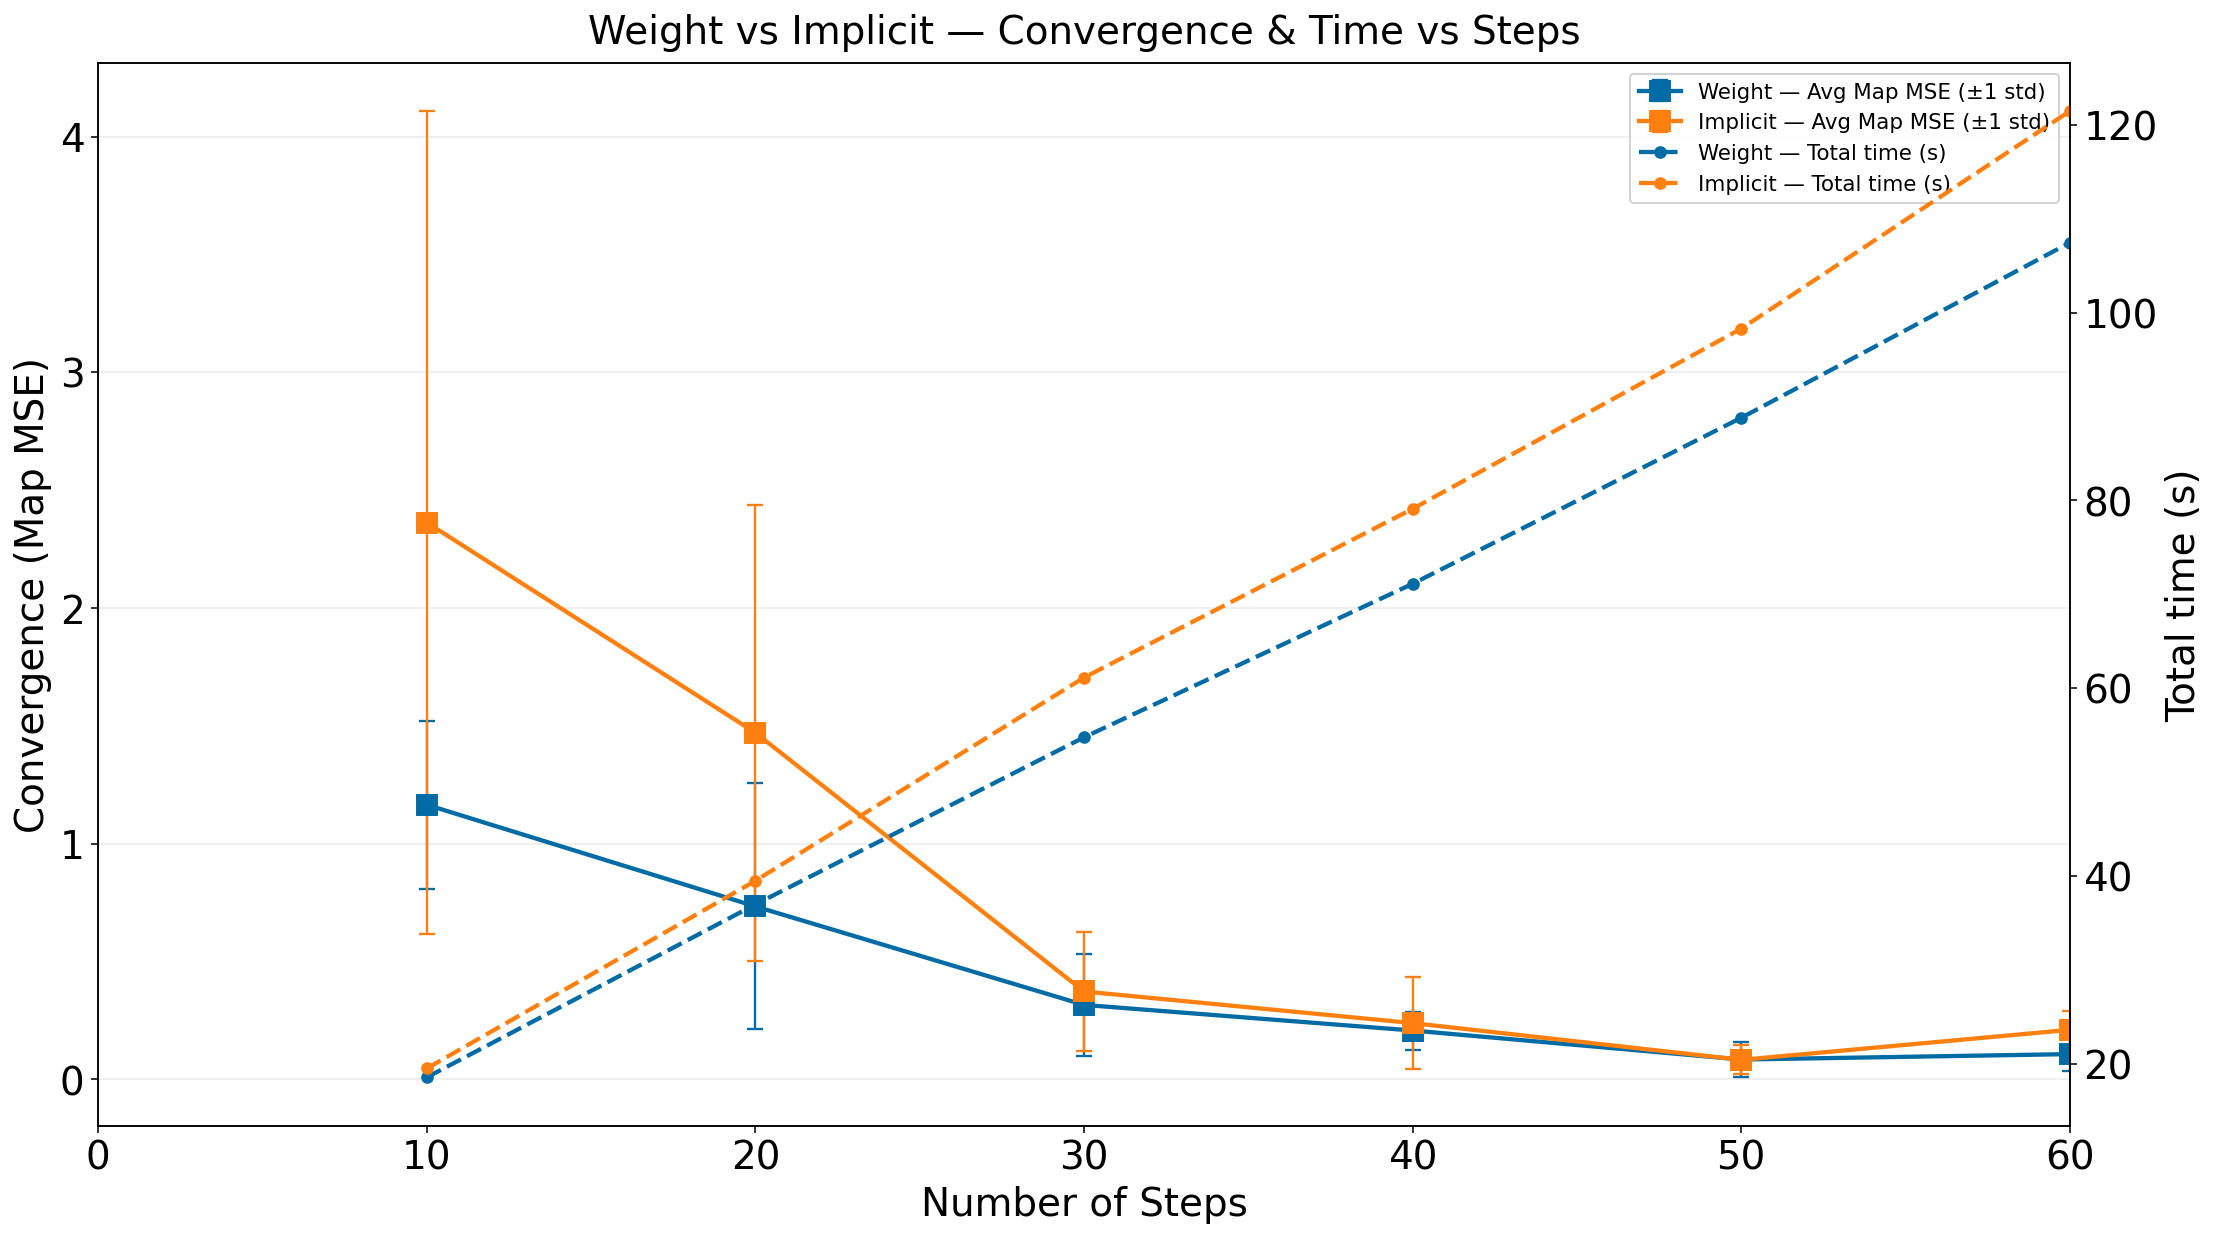

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Optional global style (matplotlib built-in, not seaborn) ----------
plt.style.use("tableau-colorblind10")  # 更耐看、对比清晰（不算你手动指定颜色）
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 200,
    "font.size": 12,
    "axes.titlesize": 20,
    "axes.labelsize": 20,
    "legend.fontsize": 11,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
})

def mean_std_from_runs(steps: np.ndarray, runs_dict: dict):
    means, stds = [], []
    for s in steps.astype(int):
        vals = np.array(runs_dict[int(s)], dtype=float)
        means.append(vals.mean())
        stds.append(vals.std(ddof=1) if len(vals) > 1 else 0.0)
    return np.array(means), np.array(stds)

# -----------------------------
# Assume you already defined:
# steps_w, time_w, mse_runs_w
# steps_i, time_i, mse_runs_i
# -----------------------------
mse_w_mean, mse_w_std = mean_std_from_runs(steps_w, mse_runs_w)
mse_i_mean, mse_i_std = mean_std_from_runs(steps_i, mse_runs_i)

# ============= Plot (refined) =============
fig, ax_left = plt.subplots(figsize=(16, 9), dpi=140)

# X axis
xmax = int(max(steps_w.max(), steps_i.max()))
xticks = sorted(set([0] + steps_w.astype(int).tolist() + steps_i.astype(int).tolist()))
ax_left.set_xlim(0, xmax)
ax_left.set_xticks(xticks)
ax_left.set_xlabel("Number of Steps")

# ---- LEFT: MSE (convergence) ----
ax_left.errorbar(
    steps_w, mse_w_mean, yerr=mse_w_std,
    fmt='-s', markersize=10, linewidth=2.2,
    capsize=4, capthick=1.2, elinewidth=1.2,
    label="Weight — Avg Map MSE (±1 std)"
)
ax_left.errorbar(
    steps_i, mse_i_mean, yerr=mse_i_std,
    fmt='-s', markersize=10, linewidth=2.2,
    capsize=4, capthick=1.2, elinewidth=1.2,
    label="Implicit — Avg Map MSE (±1 std)"
)
ax_left.set_ylabel("Convergence (Map MSE)")

# Grid: subtle
ax_left.grid(True, axis="y", linewidth=0.8, alpha=0.25)
ax_left.grid(False, axis="x")

# ---- RIGHT: Time (dashed) ----
ax_right = ax_left.twinx()
ax_right.plot(
    steps_w, time_w,
    linestyle="--", marker='o', markersize=5.5, linewidth=2.2,
    label="Weight — Total time (s)"
)
ax_right.plot(
    steps_i, time_i,
    linestyle="--", marker='o', markersize=5.5, linewidth=2.2,
    label="Implicit — Total time (s)"
)
ax_right.set_ylabel("Total time (s)")

# ---- Close the top border (spines) ----
ax_left.spines["top"].set_visible(True)
ax_right.spines["top"].set_visible(True)

# Title
ax_left.set_title("Weight vs Implicit — Convergence & Time vs Steps", pad=10)

# ---- Legend inside the plot ----
h1, l1 = ax_left.get_legend_handles_labels()
h2, l2 = ax_right.get_legend_handles_labels()
ax_left.legend(
    h1 + h2, l1 + l2,
    loc="upper right",
    frameon=True, framealpha=0.9
)

fig.tight_layout()
plt.show()

# Optional save:
# fig.savefig("compare_weight_vs_implicit_pretty_inside_legend.png", bbox_inches="tight", dpi=200)
